# Randomized benchmarking: how good is a gate?

## The problem

The benchmarking notebook measured how long a qubit keeps its state while it waits. A circuit does more than wait: it applies gates, and every gate is slightly wrong. The calibration page of a device lists a number for it, the **gate fidelity**, a value between 0 and 1 where 1 is a perfect gate. This notebook shows how that number is measured.

The simplest test is to apply a gate once and look at the output. A good gate changes the state by an error of 0.1% or less, and that is smaller than the error in preparing and reading the qubit, so the gate error cannot be seen. A second idea is to apply the same gate many times, but a small systematic error (a rotation slightly too long) then adds up coherently, and the result depends on the gate chosen more than on typical use.

**Randomized benchmarking (RB)** avoids both problems:

1. Draw $m$ gates at random from a set of 24 single-qubit gates, the Cliffords.
2. Append the one Clifford that undoes all of them. Without noise the whole sequence is the identity, so a qubit started in $|0\rangle$ ends in $|0\rangle$.
3. Run the circuit and record how often the result is 0, the **survival probability**.
4. Repeat for many random sequences and for several lengths $m$.

Each gate adds a little error, so the survival probability falls as $m$ grows. The decay rate of that curve is the gate error, and the curve is a fit again, as in the benchmarking notebook.

## The workflow

| Step | What it does | Code |
|---|---|---|
| 1. Operator | The 24 Cliffords and the decay model we fit | `ops.py` |
| 2. Encoding | Turn a random sequence of Cliffords into a circuit | `encoding.py` |
| 3. Execution | Run every sequence as one job | `execution.py` |
| 4. Analysis | Fit the decay, read off the error and the fidelity | `analysis.py` |

The same steps run from the command line with `python randomized_benchmarking/main.py`, started in `../scripts/`.

## Setup

By default this notebook runs on the Aer simulator with a depolarizing error of 0.4% on every $H$ and $S$ gate and a 2-4% read-out error. A depolarizing error replaces the qubit's state, with some probability, by a random one. Because we know the noise we put in, we can check the answer. Set `backend_name = "ibm_rensselaer"` to measure a real qubit instead.

- `lengths`: the numbers of Cliffords per sequence. The longest should let the survival fall most of the way to its floor of 0.5.
- `sequences`: random sequences per length. More sequences give a smoother average.
- `shots`: repetitions of each sequence.
- `seed`: seed of the random number generator, so the same sequences can be drawn again.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from qiskit.quantum_info import Operator

# The RB code lives in ../scripts/randomized_benchmarking.
# Run this notebook from its own folder (the Jupyter default).
sys.path.insert(0, str(Path("../scripts/randomized_benchmarking").resolve()))

import analysis
import encoding as enc
import execution
import ops

%matplotlib inline

backend_name = None  # None = Aer simulator, or e.g. "ibm_rensselaer"
qubit = 0  # physical qubit, hardware only
lengths = ops.LENGTHS
sequences = 20
shots = 1000
seed = 1

## Step 1: The operator (the gates and the decay model)

### The 24 Cliffords

A **Clifford** is one of 24 single-qubit gates. They are the gates that send each of the six states $|0\rangle, |1\rangle, |+\rangle, |-\rangle, |{+i}\rangle, |{-i}\rangle$ to another of the six. Two properties make them the right choice for RB:

- **The set is closed.** Apply any Clifford after any other and the result is again one of the 24. A random sequence of Cliffords is therefore equivalent to a single Clifford, and the gate that undoes it is also on the list.
- **They are cheap to invert.** There is a 24-entry table, so the inverse of any sequence is one lookup.

We build them from two gates, $H$ and $S$. Start from the identity, apply $H$ and $S$ to every gate found so far, and keep each new result. The search stops after 24 gates.

In [2]:
table = ops.clifford_table()
print(f"{len(table)} Cliffords found\n")
print(f"{'index':>5}  gates")
for i, (_, gates) in enumerate(table):
    print(f"{i:>5}  {' '.join(g.upper() for g in gates) or '(identity)'}")
print(f"\naverage gates per Clifford: {np.mean([len(g) for _, g in table]):.2f}")

24 Cliffords found

index  gates
    0  (identity)
    1  H
    2  S
    3  H S
    4  S H
    5  S S
    6  H S H
    7  H S S
    8  S H S
    9  S S H
   10  S S S
   11  H S H S
   12  H S S H
   13  H S S S
   14  S H S S
   15  S S H S
   16  H S H S S
   17  H S S H S
   18  S H S S H
   19  S H S S S
   20  S S H S S
   21  H S H S S H
   22  H S H S S S
   23  H S S H S S

average gates per Clifford: 3.58


Each Clifford takes between 0 and 6 gates, and 3.58 on average. We will need that number to convert the error per Clifford to the error per gate.

### The survival probability

The quantity we measure is the probability of reading 0 at the end. It is the expectation value of the projector $|0\rangle\langle 0|$, the same kind of operator as the observables of the benchmarking notebook, and the Sampler returns it directly as the fraction of shots that read 0.

### The decay model

Suppose every Clifford does its job but, with probability $1-p$, also replaces the state by a fair coin flip. After one Clifford the survival probability is $p + (1-p)/2$. After $m$ of them, the part that was never replaced is $p^m$. The rest is a coin flip, which gives 0 half the time:

$$F(m) = \tfrac12 + \tfrac12\,p^m.$$

The random choice of gates is what makes this model correct: it turns any kind of gate error, however structured, into this average behavior. Preparation and read-out are also imperfect, but they act once, no matter how long the sequence is, so they only rescale and shift the curve. We fit

$$F(m) = A\,p^m + B,$$

where $p$ is the number we want and $A$ and $B$ absorb the preparation and read-out errors. In the ideal case $A = B = \tfrac12$.

**Worked example.** Take $p = 0.99$. How long a sequence brings the survival down to 0.75, halfway between 1 and the floor 0.5?

1. Set $0.75 = \tfrac12 + \tfrac12 p^m$, so $p^m = 0.5$.
2. Take the logarithm: $m \ln p = \ln 0.5$, so $m = \ln 0.5 / \ln 0.99 = 69$ Cliffords.

**Check.** $0.99^{69} = 0.50$, so $F = 0.75$. Each Clifford loses 1% of the remaining signal, and 69 of them lose half.

In [3]:
p = 0.99
m = np.log(0.5) / np.log(p)
print(f"m = {m:.1f}")
print(f"F(69) = {0.5 + 0.5 * p**69:.3f}")

m = 69.0
F(69) = 0.750


### From the decay rate to the gate fidelity

The signal that survives one Clifford is the fraction $p$. The rest, $1-p$, is replaced by a random state, and a random state is still correct half the time for a single qubit. The **error per Clifford** is the part that is actually wrong:

$$r = \frac{1 - p}{2}.$$

(For a system with $d$ outcomes the 2 is replaced by $d/(d-1)$. A qubit has $d = 2$ outcomes, 0 and 1.) The **fidelity** of the Clifford is $1 - r$. If a Clifford is made of 3.58 gates on average, the error per gate is about $r / 3.58$. For $p = 0.99$ this gives $r = 0.005$, a fidelity of 99.5% per Clifford, and an error of 0.14% per gate.

**Stop and think.** A qubit is read out wrong 3% of the time. Would you expect that to change $p$? Would it change $A$ or $B$? The last section of this notebook tests the answer.

## Step 2: Encoding (one random sequence)

A sequence is a list of $m$ random Clifford indices plus one more that undoes them. To find the last one, compose all $m$ Cliffords into one, take its inverse, and look it up in the table. Each index is then written out as its $H$ and $S$ gates. A barrier between Cliffords stops the compiler from merging neighbors, and a measurement closes the circuit.

Clifford indices: [11, 12, 18, 22, 18] (the last one is the inverse)


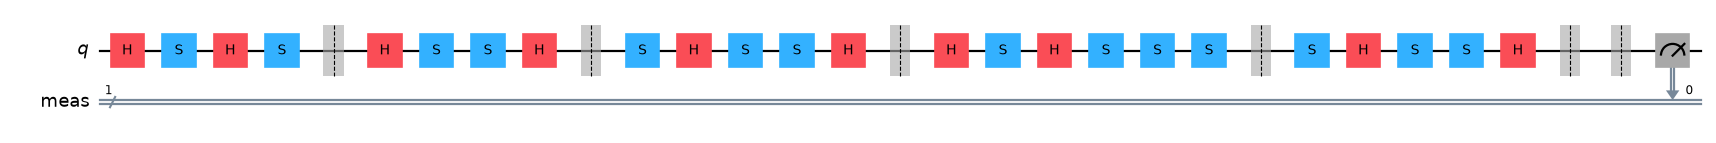

In [4]:
rng = np.random.default_rng(seed)
sequence = ops.random_sequence(4, rng)
print("Clifford indices:", sequence, "(the last one is the inverse)")

circuit = enc.build_circuit(sequence)
display(circuit.draw("mpl", fold=40, scale=0.8))
plt.close()

Check that the sequence is the identity. We compare the circuit without its measurement against the identity matrix, and run it on a noiseless simulator.

In [5]:
from qiskit_aer import AerSimulator

unitary = Operator(circuit.remove_final_measurements(inplace=False))
print("equals the identity (up to a global phase):", unitary.equiv(Operator(np.eye(2))))

counts = AerSimulator().run(circuit, shots=1000).result().get_counts()
print("noiseless counts:", counts)

equals the identity (up to a global phase): True
noiseless counts: {'0': 1000}


**Stop and think.**

1. **The inverse is what makes the test simple.** The answer is always 0, whatever the random gates were, so a single number (the survival probability) tells us about the noise.
2. **The compiler must not shorten the sequence.** The whole circuit is the identity, so an optimizer would delete it. `transpile_for` runs with the optimizer off, and the barriers mark the boundaries.
3. **Averaging over many sequences matters.** One sequence fixes one particular order of gates, and its error can be better or worse than typical. The model above describes the average over the random choice, so we draw many sequences for each length.

## Step 3: Execution

Every sequence of every length is one circuit, so 10 lengths of 20 sequences make 200 circuits. They go out as **one job**, because on hardware the queue wait is paid once per job.

On the simulator the noise is a depolarizing error on each $H$ and $S$ and a read-out error. The decay rate that this noise gives follows from the numbers. An error $e$ on a gate multiplies the signal by $(1-e)$, so a Clifford of $k$ gates multiplies it by $(1-e)^k$. A random Clifford is any of the 24 with equal probability, so $p$ is the average of $(1-e)^k$ over the table.

In [6]:
data = execution.run(lengths, sequences, shots, backend_name, qubit if backend_name else None, seed)

print(f"{len(lengths) * sequences} circuits, {data['seconds']:.1f} s")
print(f"{'length':>7} {'mean survival':>14} {'spread (std)':>13}")
for m, runs in data["survival"].items():
    print(f"{m:>7} {np.mean(runs):>14.3f} {np.std(runs):>13.3f}")

200 circuits, 1.2 s
 length  mean survival  spread (std)
      1          0.967         0.010
      5          0.941         0.009
     10          0.907         0.013
     20          0.862         0.019
     40          0.772         0.016
     80          0.656         0.022
    120          0.588         0.016
    160          0.560         0.017
    240          0.529         0.015
    320          0.515         0.012


## Step 4: Analysis

### The fit

We average the survival over the sequences of each length and fit $A\,p^m + B$ to the averages with `scipy.optimize.curve_fit`, as in the benchmarking notebook. The error of $p$ comes from the covariance matrix. The first figure shows every sequence as a gray dot, the mean of each length, and the fit. The lower panel shows the residuals, data minus fit. They should scatter around zero with no trend.

                                              fit   built in
decay rate p                      0.98561 +/- 0.00031    0.98576
error per Clifford r              0.00719 +/- 0.00015    0.00712
Clifford fidelity 1 - r           0.99281
error per gate                    0.00201 (3.58 gates per Clifford)
A, B                                0.461, 0.512


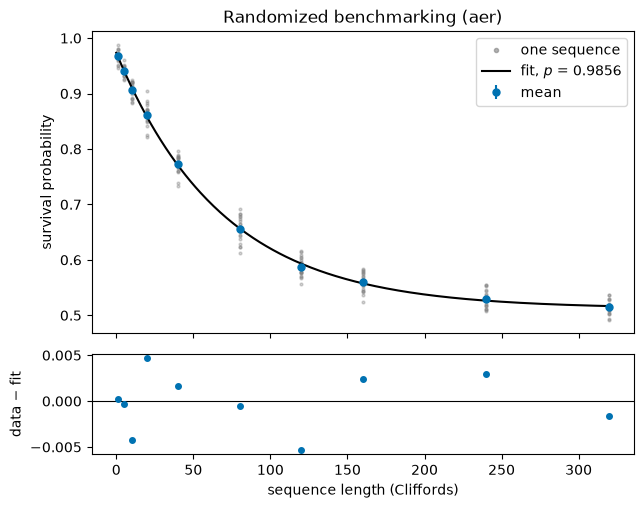

In [7]:
result = analysis.fit(data)
analysis.print_table(data, result)

fig = analysis.plot_fit(data, result)
fig.axes[0].set_title(f"Randomized benchmarking ({data['backend']})")
display(fig)
plt.close(fig)

The table gives the decay rate $p$, the error per Clifford $r$, the fidelity $1 - r$, and the error per gate. On the simulator the column "built in" is the value computed from the noise we put in, and the fit should agree with it within a few standard errors.

### Does the read-out error matter?

Run the same gates with two read-out errors: none, and 5% / 10%. The curves start and end at different heights, which is $A$ and $B$ at work, but the decay rate should be the same.

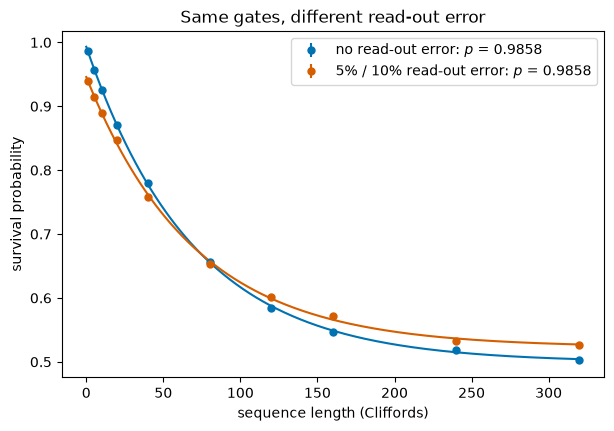

no read-out error          p = 0.9858 +/- 0.0002   A = 0.494   B = 0.499
5% / 10% read-out error    p = 0.9858 +/- 0.0004   A = 0.423   B = 0.523


In [8]:
runs = {}
for label, readout in [("no read-out error", (0.0, 0.0)), ("5% / 10% read-out error", (0.05, 0.10))]:
    d = execution.run(lengths, sequences, shots, None, None, seed, readout=readout)
    runs[label] = (d, analysis.fit(d))

fig = analysis.plot_spam(runs)
display(fig)
plt.close(fig)

for label, (d, r) in runs.items():
    p, e = r["params"]["p"], r["errors"]["p"]
    print(f"{label:<26} p = {p:.4f} +/- {e:.4f}   A = {r['params']['amp']:.3f}   B = {r['params']['offset']:.3f}")

The decay rates agree within their errors, while $A$ and $B$ changed. This is why RB is the standard way to quote gate fidelity: it separates the error of the gates from the error of preparing and reading the qubit. A test that applied one gate and compared the output would see the read-out error instead.

## Reading the results

- **The fit recovers the built-in error.** The fitted $p$ lies within a few standard errors of the built-in 0.9858, and the error per Clifford is about 0.7%. Reruns with another `seed` move the fit by about its error bar.
- **A and B are not 0.5.** The preparation and read-out errors move them, and the fit takes care of it. If $A$ were close to 0, the sequences would be too long and the curve would have decayed before the first point.
- **The error per gate is an estimate.** It divides the error per Clifford by the average gate count, which assumes all gates are equally bad. On hardware the compiler writes each Clifford in the device's native gates ($\sqrt X$, $X$, and virtual $R_Z$ rotations, which are free), and the count is taken from the compiled circuits.
- **The number is an average.** It tells you about typical gates in random sequences. It does not tell you which gate is the worst or what kind of error it has. Interleaved RB (not covered here) measures a single chosen gate.

On hardware, expect a curve that does not fall to exactly 0.5 within the longest sequence (choose longer sequences), and spread between sequences that is larger than the shot noise alone. A residual pattern that is not scatter means the noise is not simple depolarizing, for example because of slow drift in the qubit.

## What to try next

1. Change `lengths` to `(1, 2, 4, 8, 16)`. The curve barely decays. What does the fit return for $p$, and how large is its error? What does this say about choosing the longest sequence?
2. Set `sequences = 5`, then `100`. How does the error of $p$ change?
3. In `ops.py` change `SIM_GATE_ERROR` to `0.01` and rerun. Predict $r$ first, using the table of gate counts.
4. Change `shots` to 100. Which part of the figure gets noisier, the spread within a length or the trend of the means?
5. Compare the error per Clifford with $1 - e^{-t/T_2}$ for the duration $t$ of a Clifford. How do the gate error and the decoherence compare on `ibm_rensselaer`?
6. Run on `ibm_rensselaer` with `qubit = 0`, then a different qubit. Do the fidelities agree with the calibration page?
7. Hardware only: run twice on the same qubit. How large is the difference compared with the error bar of one fit?